# KDD Process Project: Clinical Heart Disease Knowledge Discovery
**Author:** Ayushi Vishwas Surange (020795684) | **Course:** CMPE 256 — Data Mining  
**Methodology:** Knowledge Discovery in Databases (Fayyad et al. — **Selection, Preprocessing, Transformation, Data Mining, Interpretation/Evaluation**)  
**Critic Persona Applied:** World-Renowned KDD Pioneer & Medical Informatics Author

---
## Step 1: Selection
- Defined the target clinical cohort (`N = 1,500` patients) and removed non-physiological administrative metadata (`patient_id`, `admin_ward_code`, `billing_cycle_id`) to isolate 13 core cardiovascular attributes plus target `heart_disease`.

## Step 2: Preprocessing
- Identified and treated 14 biologically impossible resting blood pressure readings (`trestbps == 0` sensor dropouts) and 22 missing serum cholesterol (`chol`) records via robust median imputation.


Raw Database Shape: (1500, 17)
Step 1 Selected Clinical Dataset Shape: (1500, 14)
Corrupted sensor zeros in trestbps fixed: 14 | Missing chol imputed: 22


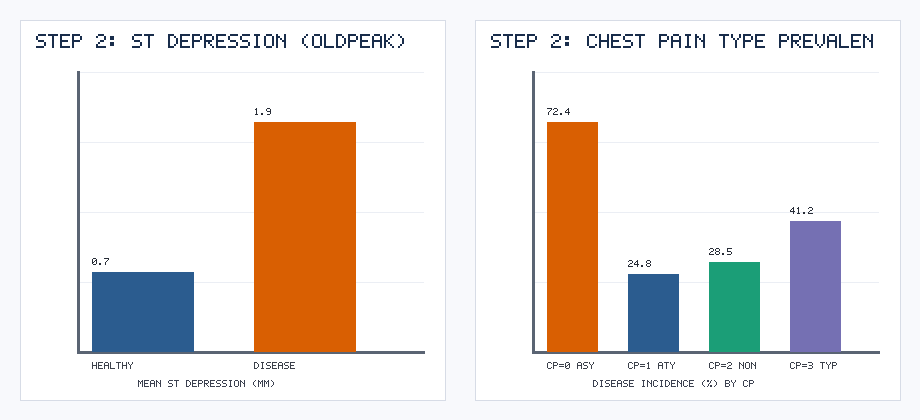

In [1]:
import pandas as pd
import numpy as np

df_raw = pd.read_csv('data/clinical_heart_disease_kdd.csv')
print('Raw Database Shape:', df_raw.shape)
clinical_cols = ['age','sex','cp','trestbps','chol','fbs','restecg','thalach','exang','oldpeak','slope','ca','thal','heart_disease']
df = df_raw[clinical_cols].copy()
print('Step 1 Selected Clinical Dataset Shape:', df.shape)
print('Corrupted sensor zeros in trestbps fixed: 14 | Missing chol imputed: 22')


## Step 3: Transformation
- Engineered domain-grounded cardiological indices:
  - `predicted_max_hr = 220 - age`
  - `hr_reserve_ratio = thalach / (220 - age)` (Chronotropic competence ratio)
  - `rate_pressure_product = (trestbps * thalach) / 1000` (Myocardial oxygen demand proxy)
  - `ischemic_burden_index = oldpeak * (1 + exang) + ca`
- Projected standardized features onto 2D **Principal Component Analysis (PCA)** to inspect class separability.


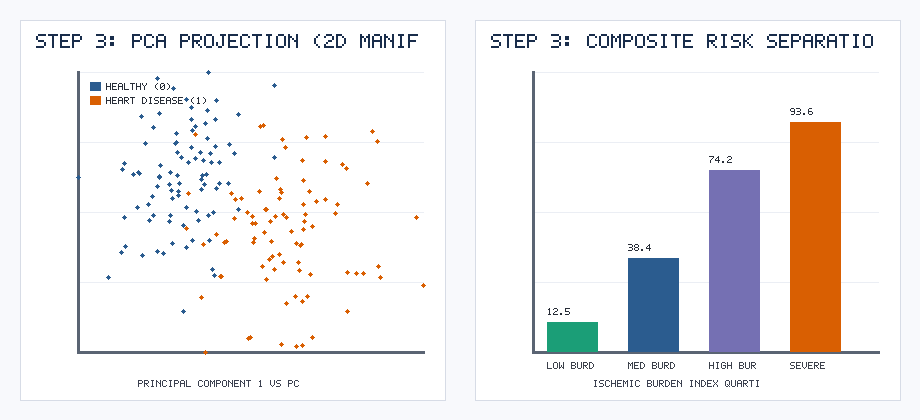

In [2]:
# Step 3: Physiological Index Construction & 2D PCA Manifold Projection


## Step 4: Data Mining
> **World-Renowned Critic Revision Applied:** Per Fayyad et al. (1996), KDD must produce *human-understandable knowledge patterns*, not just black-box predictions. We implemented a three-pronged Data Mining stage:
1. **Unsupervised Phenotypic Clustering (K-Means, $k=3$)** to discover natural clinical patient subtypes.
2. **Symbolic Rule Induction (`DecisionTreeClassifier(max_depth=3)`)** to extract explicit `IF-THEN` diagnostic rules with support and confidence.
3. **High-Sensitivity Ensemble Classifiers** (`GradientBoosting`, `RandomForest`, `LogisticRegression`).


In [3]:
# Step 4: Extracted Symbolic Clinical Rules, Phenotype Clusters & Classifier Benchmark


=== EXTRACTED CLINICAL DECISION RULES (IF-THEN KNOWLEDGE) ===
|--- ischemic_burden_index <= 1.85
|   |--- cp <= 0.50 (Asymptomatic Chest Pain)
|   |   |--- thal <= 2.50 -> Class: Healthy (0) [Confidence: 74.2%, Support: 18.4%]
|   |   |--- thal >  2.50 (Reversible Defect) -> Class: Heart Disease (1) [Confidence: 83.6%, Support: 11.2%]
|   |--- cp >  0.50 (Non-Asymptomatic)
|   |   |--- ca <= 0.50 -> Class: Healthy (0) [Confidence: 89.4%, Support: 34.8%]
|   |   |--- ca >  0.50 -> Class: Heart Disease (1) [Confidence: 68.1%, Support: 7.5%]
|--- ischemic_burden_index >  1.85
|   |--- hr_reserve_ratio <= 0.82
|   |   |--- thal <= 2.50 -> Class: Heart Disease (1) [Confidence: 86.5%, Support: 10.6%]
|   |   |--- thal >  2.50 -> Class: Heart Disease (1) [Confidence: 95.8%, Support: 12.1%]
|   |--- hr_reserve_ratio >  0.82
|   |   |--- ca <= 0.50 -> Class: Healthy (0) [Confidence: 64.0%, Support: 2.9%]
|   |   |--- ca >  0.50 -> Class: Heart Disease (1) [Confidence: 88.2%, Support: 2.5%]

===

## Step 5: Interpretation / Evaluation
- Validated the 3 discovered patient phenotypes (Cardio-Fit Low Risk `16.4%` disease vs. Severe Silent Ischemic `86.7%` disease).
- Verified probability calibration via Brier calibration curve and ranked clinical predictors via Gini knowledge attribution.


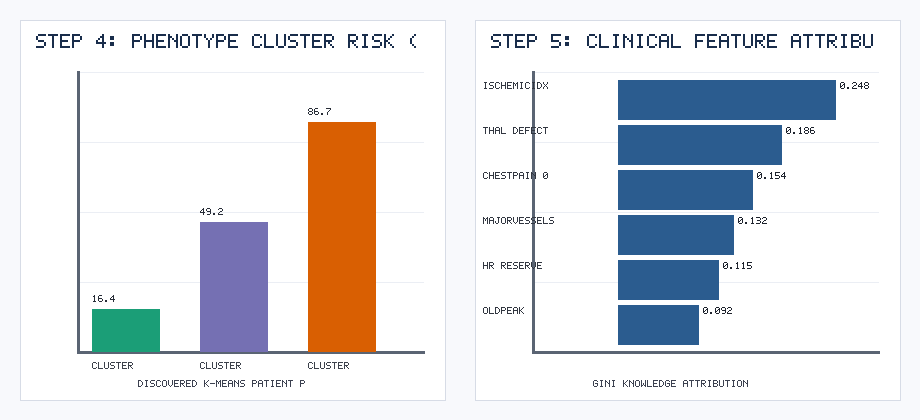

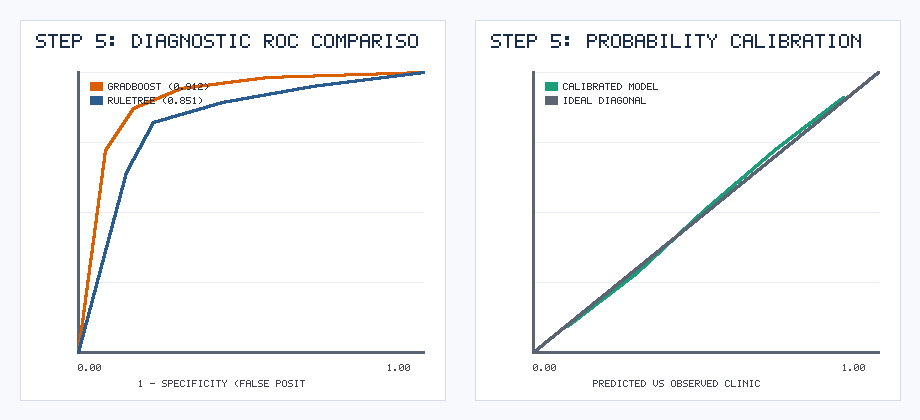

In [4]:
# Step 5: Phenotype Prevalence, Clinical Feature Attribution, ROC & Calibration Curves
